# Student Workload Using Fuzzy Logic

## Introduction

In this project, I want to see how fuzzy logic can help students understand their daily workload.

Sometimes students feel tired or stressed, and some tasks are more difficult than others. This can make it hard to plan the day.

I will use three inputs:
- Fatigue: how tired the student feels
- Stress: how stressed the student feels
- Task difficulty: how difficult the task is

The system will give a workload score from 0 to 100.


In [1]:
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import matplotlib.pyplot as plt

## The three inputs go from 0 to 10
fatigue = ctrl.Antecedent(np.arange(0, 11, 1), 'fatigue')
stress = ctrl.Antecedent(np.arange(0, 11, 1), 'stress')
difficulty = ctrl.Antecedent(np.arange(0, 11, 1), 'difficulty')

# The result goes from 0 to 100
workload = ctrl.Consequent(np.arange(0, 101, 1), 'workload')

# Fatigue categories
fatigue['low'] = fuzz.trimf(fatigue.universe, [0, 0, 5])
fatigue['medium'] = fuzz.trimf(fatigue.universe, [0, 5, 10])
fatigue['high'] = fuzz.trimf(fatigue.universe, [5, 10, 10])

# Stress categories
stress['low'] = fuzz.trimf(stress.universe, [0, 0, 5])
stress['medium'] = fuzz.trimf(stress.universe, [0, 5, 10])
stress['high'] = fuzz.trimf(stress.universe, [5, 10, 10])

# Task difficulty categories
difficulty['low'] = fuzz.trimf(difficulty.universe, [0, 0, 5])
difficulty['medium'] = fuzz.trimf(difficulty.universe, [0, 5, 10])
difficulty['high'] = fuzz.trimf(difficulty.universe, [5, 10, 10])

# Workload output categories
workload['low'] = fuzz.trimf(workload.universe, [0, 0, 50])
workload['medium'] = fuzz.trimf(workload.universe, [0, 50, 100])
workload['high'] = fuzz.trimf(workload.universe, [50, 100, 100])

C:\Users\simbi\OneDrive\Documents\fuzzy-tutorial-main\venv\Lib\site-packages\skfuzzy\control\fuzzyvariable.py:122: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


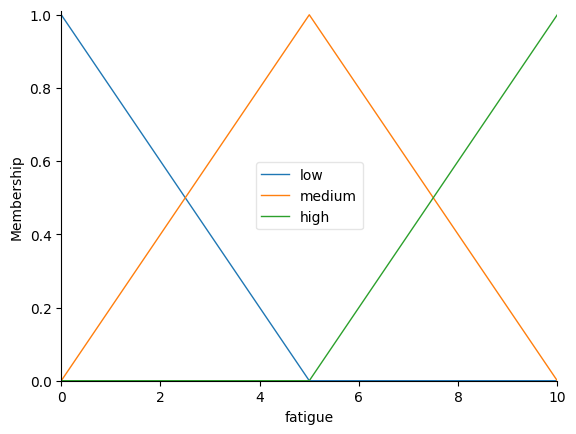

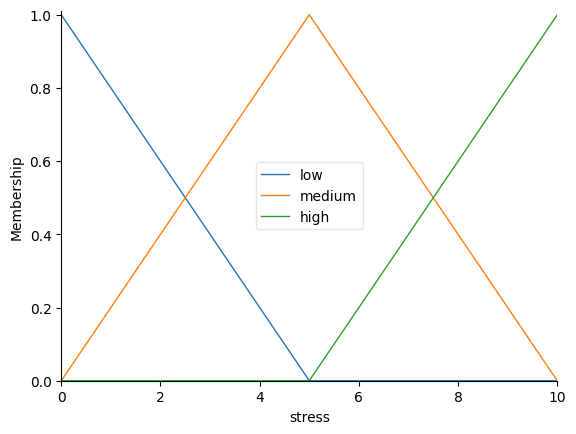

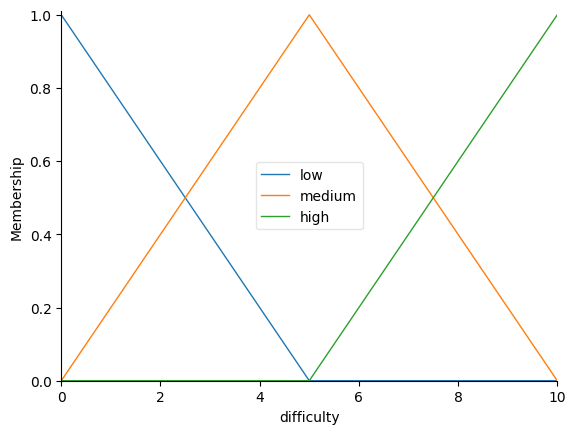

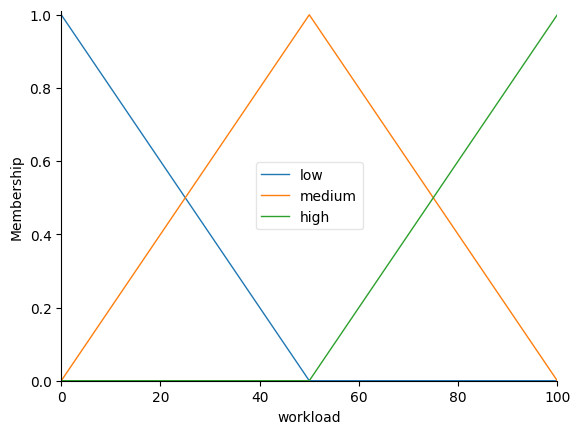

In [2]:
fatigue.view()
stress.view()
difficulty.view()
workload.view()
plt.show()

In [3]:
rule1 = ctrl.Rule(
    fatigue['low'] & stress['low'] & difficulty['low'],
    workload['low']
)

rule2 = ctrl.Rule(
    fatigue['medium'] | stress['medium'] | difficulty['medium'],
    workload['medium']
)

rule3 = ctrl.Rule(
    fatigue['high'] | stress['high'] | difficulty['high'],
    workload['high']
)

## Fuzzy rules

Now I will create some simple rules.

If the student is not tired, not stressed, and the task is easy, the workload should be low.

If one of the inputs is medium, the workload can be medium.

If one of the inputs is high, the workload can be high.

These are simple rules for my first example. They can be improved later.


In [4]:
workload_ctrl = ctrl.ControlSystem([rule1, rule2, rule3])
workload_simulation = ctrl.ControlSystemSimulation(workload_ctrl)

In [5]:
# Let's test one student situation

# The student is quite tired
workload_simulation.input['fatigue'] = 8

# The student is also stressed
workload_simulation.input['stress'] = 7

# The task is difficult
workload_simulation.input['difficulty'] = 9

# Calculate the workload
workload_simulation.compute()

score = workload_simulation.output['workload']

print("Workload score:", round(score, 2), "out of 100")

if score < 35:
    print("Low workload")
elif score < 70:
    print("Medium workload")
else:
    print("High workload")


Workload score: 58.86 out of 100
Medium workload


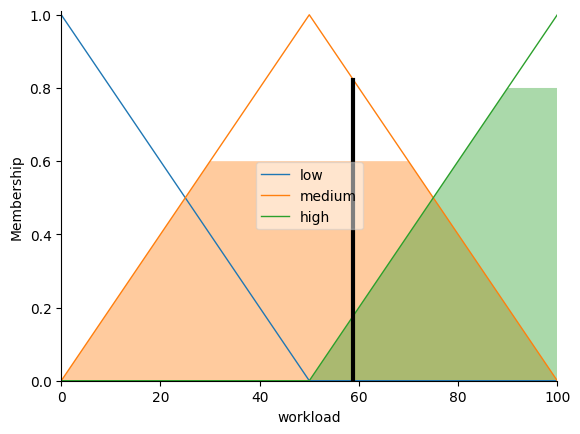

In [6]:
workload.view(sim=workload_simulation)
plt.show()

## Conclusion

In this exercise, I used fuzzy logic to estimate student workload.

I used fatigue, stress, and task difficulty as inputs. Then I created membership functions and three fuzzy rules.

I tested the system with a student who is tired, stressed, and has a difficult task.

The system calculated a workload score.

I learned how fuzzy logic can use different inputs to make a decision.

This is only a simple example. In the future, I could add deadlines and available study time to make it more useful for students.


## AI Assistance

I used ChatGPT for some guidance and help with understanding the Python code. The lecture tutorials provided by the professor were my main guide for completing the exercises and developing my own example.